# Carteras con cuatro activos reales

En este notebook, vamos a construir carteras de inversión con cuatro activos reales. Aprenderemos a calcular la rentabilidad y volatilidad usando matrices y a generar múltiples carteras con pesos aleatorios para los activos. 

In [16]:
import math
import numpy as np

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

## 1. Descarga de precios

In [17]:
filename = "https://raw.githubusercontent.com/alfonso-santos/Python-aplicado-gestion-carteras/fernando/Tema_2/data/tr_eikon_eod_data.csv"
raw = pd.read_csv(filename, index_col=0, parse_dates=True)
raw.head()

,AAPL.O,MSFT.O,INTC.O,AMZN.O,GS.N,SPY,.SPX,.VIX,EUR=,XAU=,GDX,GLD
Date,,,,,,,,,,,,
2010-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.4323,1096.35,NaN,NaN
2010-01-04,30.572827,30.950,20.88,133.90,173.08,113.33,1132.99,20.04,1.4411,1120.00,47.71,109.80
2010-01-05,30.625684,30.960,20.87,134.69,176.14,113.63,1136.52,19.35,1.4368,1118.65,48.17,109.70
2010-01-06,30.138541,30.770,20.80,132.25,174.26,113.71,1137.14,19.16,1.4412,1138.50,49.34,111.51
2010-01-07,30.082827,30.452,20.60,130.00,177.67,114.19,1141.69,19.06,1.4318,1131.90,49.10,110.82


In [18]:
symbols = ["SPY", "GLD", "AAPL.O", "MSFT.O"]
data = raw[symbols].dropna()
data.head()

,SPY,GLD,AAPL.O,MSFT.O
Date,,,,
2010-01-04,113.33,109.80,30.572827,30.950
2010-01-05,113.63,109.70,30.625684,30.960
2010-01-06,113.71,111.51,30.138541,30.770
2010-01-07,114.19,110.82,30.082827,30.452
2010-01-08,114.57,111.37,30.282827,30.660


### Visualización

Para comparar visualmente todas las series de precios, es útil que empiecen desde el mismo valor, para ello, dividimos los precios actuales con los del instante de tiempo inicial `data.iloc[0]`.

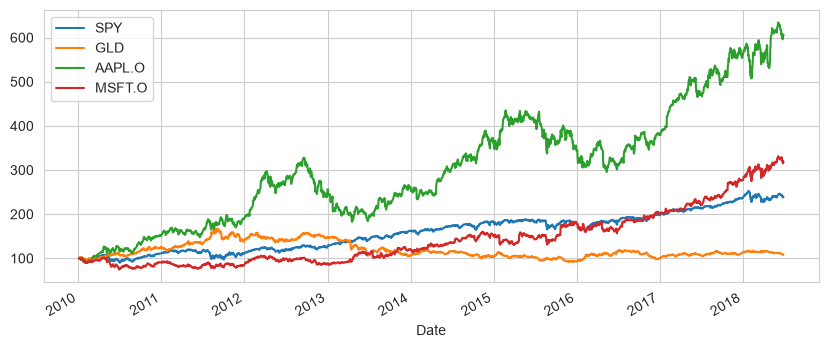

In [21]:
(data / data.iloc[0] * 100).plot(figsize=(10, 4))
plt.show()

Como siempre, vamos a calcular las rentabilidades logarítmicas y posteriormente representar sus histogramas.

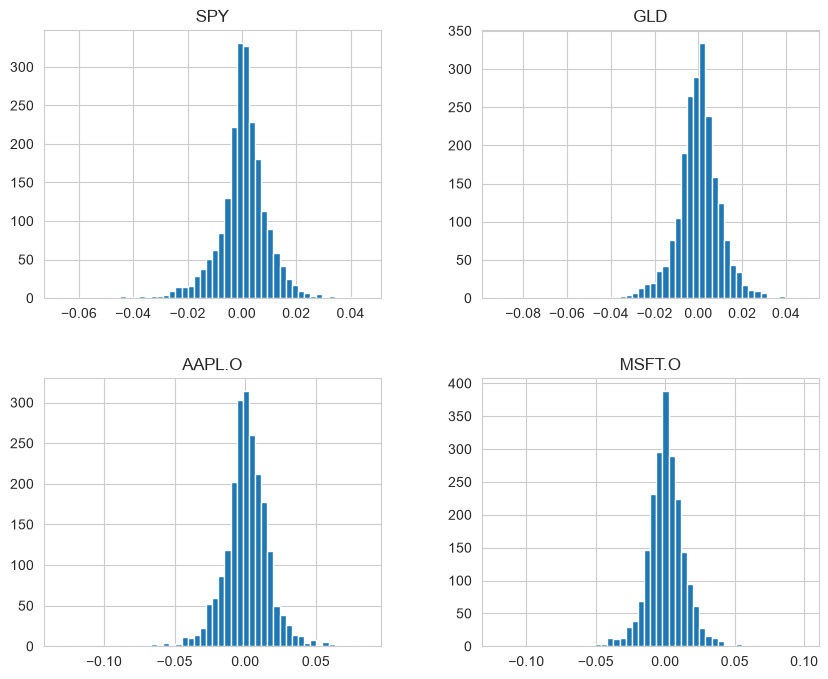

In [22]:
rets = np.log(data).diff().dropna()
rets.hist(bins=50, figsize=(10, 8))
plt.show()

**Rentabilidad** de la cartera $E(\tilde R_p)=\sum_{i=1}^{N}w_i E(\tilde R_i)$

$\sigma²(\tilde R_p)=\begin{pmatrix}w_1 & w_2 & ... & w_N\end{pmatrix} \begin{pmatrix}\sigma_1^2 & \sigma_{12}^2 & ... & \sigma_{1N}^2\\ 
 \sigma_{21}^2& \sigma_2^2 &...  & \sigma_{2N}^2\\ ... & ... & ... & ...\\  \sigma_{N1}^2& \sigma_{N2}^2 & ... & \sigma_N^2\end{pmatrix} \begin{pmatrix}w_1 \\w_2  \\...  \\ w_N\end{pmatrix} = \mathbf{w}^T\mathbf{C}\mathbf{w}$

**EJERCICIO** Crea una cartera equiponderada con cuatro activos

In [23]:
noa = len(symbols) # contamos el número de activos
print('Número de activos', noa)

# Creamos una cartera equiponderada
weights = np.array(noa * [1. / noa,])
weights


mean=rets.mean()
mean

Número de activos 4


SPY       0.000408
GLD       0.000036
AAPL.O    0.000843
MSFT.O    0.000542
dtype: float64

In [24]:
ret_port=rets.mean()* 252 @ weights.T
print(f"La rentabilidad esperada de la cartera equiponderada:{ret_port:.4f}")

La rentabilidad esperada de la cartera equiponderada:0.1153


In [25]:
cov=rets.cov()
cov

,SPY,GLD,AAPL.O,MSFT.O
SPY,8.705878e-05,2.470088e-07,0.000083,0.000088
GLD,2.470088e-07,1.040027e-04,0.000006,-0.000001
AAPL.O,8.348619e-05,6.002633e-06,0.000253,0.000093
MSFT.O,8.826834e-05,-1.376963e-06,0.000093,0.000202


In [26]:
sigma_port=np.sqrt(weights @ cov*252 @ weights.T)
print(f"La volatilidad de la cartera equiponderada:{sigma_port:.4f}")

La volatilidad de la cartera equiponderada:0.1366


**Ejercicio** A partir de los datos descargados de los cuatro activos, genera 5000 carteras aleatorias y represéntalas.

In [27]:
# Generamos pesos aleatorios para 5000 carteras de 4 activos.
num_carteras = 5000
num_activos = 4

rng = np.random.default_rng(42)
pesos = rng.random(size=(num_carteras, num_activos))
pesos = pesos / np.sum(pesos, axis=1, keepdims=True)

pesos.shape

(5000, 4)

In [28]:
rets.shape

(2137, 4)

In [29]:
# Calculamos los retornos de las carteras utilizando multiplicación matricial.
retornos_diarios_carteras = rets @ pesos.T  # (2137, 4) @ (4, 5000) = (2137, 5000)

retornos_diarios_carteras.shape

(2137, 5000)

In [30]:
# Calculamos el retorno esperado de cada cartera.
retornos_mean_carteras = retornos_diarios_carteras.mean(axis=0)

retornos_mean_carteras.shape

(5000,)

In [31]:
# Calculamos el riesgo de cada cartera.
std_carteras = retornos_diarios_carteras.std(axis=0)

std_carteras.shape

(5000,)

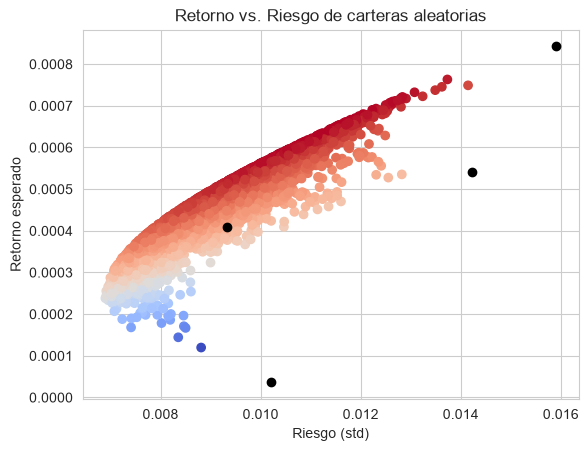

In [32]:
# Graficamos rentabilidad vs. riesgo.
plt.scatter(x=std_carteras, y=retornos_mean_carteras, c=retornos_mean_carteras / std_carteras, marker="o", cmap="coolwarm")

# Graficamos los activos individuales.
for asset_name in rets.columns:
    asset_ret = rets[asset_name].mean()
    aset_std = rets[asset_name].std()

    plt.plot(aset_std, asset_ret, "o", color="black")

plt.xlabel("Riesgo (std)")
plt.ylabel("Retorno esperado")
plt.title("Retorno vs. Riesgo de carteras aleatorias")
plt.show()